# CCA 3 – Computer Vision Assignment
## Image Restoration, Segmentation, Feature Extraction, Object Recognition and Motion Estimation

**Student:** Aditi Deshpande
**Environment:** Jupyter Notebook  
**Language:** Python

### Project overview
This consolidated notebook combines the useful content from the two supplied notebook versions, removes duplicate setup and obsolete cells, and implements the four practical tasks in the CCA 3 assignment: image restoration and segmentation, HOG/SIFT feature extraction, Haar Cascade and YOLO object recognition, and video motion estimation.

### Input files
Keep a `data` folder beside this notebook containing:
- `original_portrait.png` – your original photograph.
- `original_video.mp4` – your self-recorded video (the assignment requests approximately 15–30 seconds).
- `yolo11n.pt` – optional local YOLO weights; if absent, Ultralytics may download them.
- `second_same_scene_photo.jpg` – a second original photograph of the same object or scene (required for the first SIFT matching experiment).
- `watershed_objects.png` – optional suitable image with multiple/touching objects for watershed. If absent, the portrait is used as a demonstration and the notebook warns that a more suitable image is needed.

**Important:** The notebook cannot create genuine second original photographs or a self-recorded video. Add your own files before final submission.


**Project update:** This is a separate copy of the corrected notebook. The supplied second photograph is included at `data/second_same_scene_photo.jpg`. A final submission checklist is included at the end. The earlier corrected notebook has not been modified.


### Input-specific note
The supplied pair contains the same person photographed in two different scenes and outfits (one formal studio portrait and one casual indoor portrait). They are used as the two provided images for SIFT comparison, but they are **not the same scene/object capture**; interpret cross-image matches cautiously. The video is the supplied Coverr twilight-city sample, not a verified self-recorded video.


## 1. Imports, paths and input verification


C:\Users\Aishwarya\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been deprecated
  "class": algorithms.Blowfish,


Portrait dimensions: 1024 x 1536
Video file exists: True
Second same-scene photograph exists: True
Optional watershed objects image exists: False


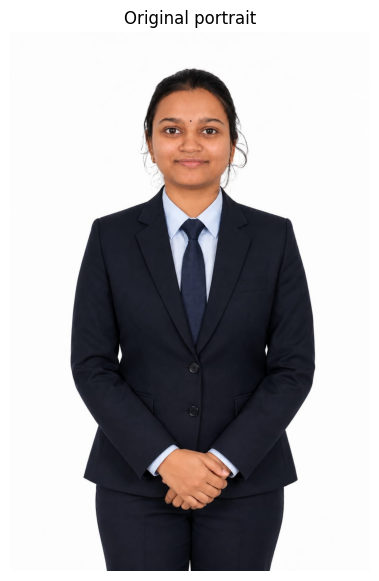

OpenCV version: 4.10.0


In [41]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from skimage.feature import hog
from IPython.display import display

ROOT = Path.cwd()
DATA = ROOT / "data"
OUT = ROOT / "outputs"
for folder in ["task1", "task2", "task3", "task4"]:
    (OUT / folder).mkdir(parents=True, exist_ok=True)

PORTRAIT_PATH = DATA / "original_portrait.png"
VIDEO_PATH = DATA / "original_video.mp4"
SECOND_PHOTO_PATH = DATA / "second_same_scene_photo.jpg"
WATERSHED_PATH = DATA / "watershed_objects.png"

portrait_bgr = cv2.imread(str(PORTRAIT_PATH))
if portrait_bgr is None:
    raise FileNotFoundError(f"Portrait not found: {PORTRAIT_PATH.resolve()}")
portrait_rgb = cv2.cvtColor(portrait_bgr, cv2.COLOR_BGR2RGB)
portrait_gray = cv2.cvtColor(portrait_bgr, cv2.COLOR_BGR2GRAY)
height, width = portrait_gray.shape

print(f"Portrait dimensions: {width} x {height}")
print("Video file exists:", VIDEO_PATH.exists())
print("Second same-scene photograph exists:", SECOND_PHOTO_PATH.exists())
print("Optional watershed objects image exists:", WATERSHED_PATH.exists())
plt.figure(figsize=(6, 7))
plt.imshow(portrait_rgb)
plt.title("Original portrait")
plt.axis("off")
plt.show()


print("OpenCV version:", cv2.__version__)

# UNIT 3 – Image Restoration and Segmentation

## Task 1A. Add Gaussian and salt-and-pepper noise
Gaussian noise models random intensity variation. Salt-and-pepper noise replaces selected pixels with black or white values. A fixed random seed makes the experiment reproducible.

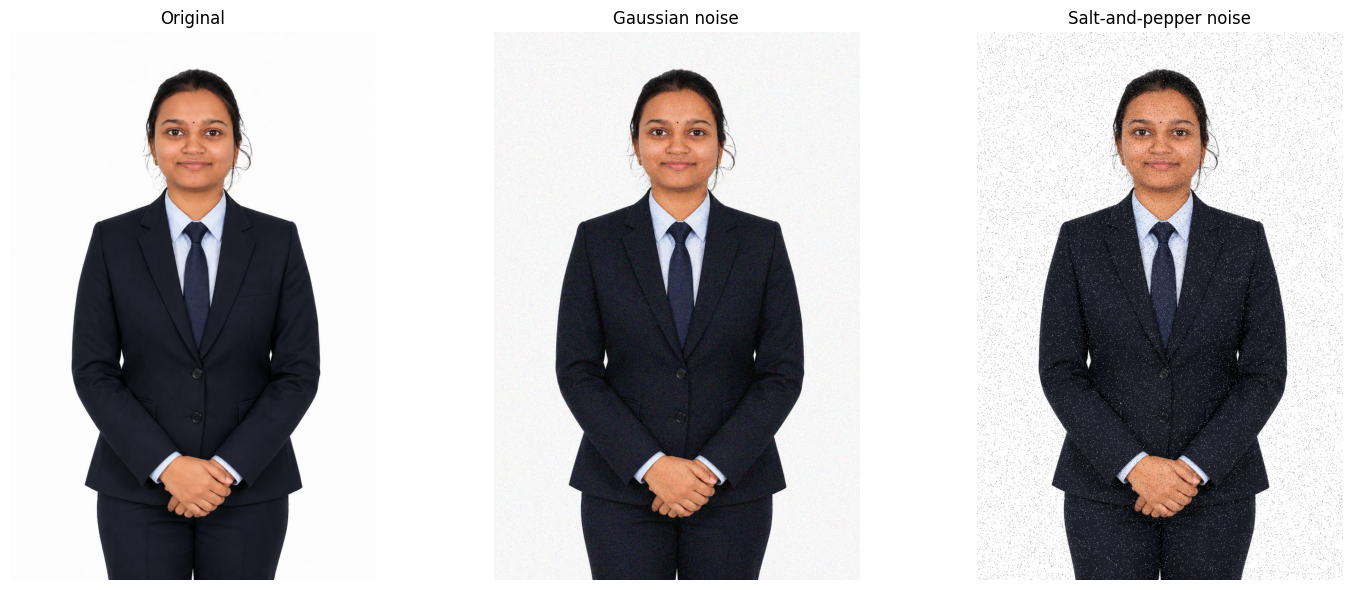

In [42]:
# Generate Gaussian and salt-and-pepper noise with memory-efficient processing.
rng = np.random.default_rng(42)

height, width = portrait_rgb.shape[:2]
gaussian_noisy = np.empty_like(portrait_rgb, dtype=np.uint8)
chunk_rows = 32  # Reduce to 16 if memory is still limited.

for start in range(0, height, chunk_rows):
    end = min(start + chunk_rows, height)
    block = portrait_rgb[start:end].astype(np.float32)
    noise = rng.standard_normal(block.shape, dtype=np.float32) * 18
    gaussian_noisy[start:end] = np.clip(block + noise, 0, 255).astype(np.uint8)

sp_noisy = portrait_rgb.copy()
noise_count = int(0.035 * height * width)
indices = rng.choice(height * width, size=noise_count, replace=False)
flat_sp = sp_noisy.reshape(-1, 3)
half = noise_count // 2
flat_sp[indices[:half]] = 255
flat_sp[indices[half:]] = 0

fig, ax = plt.subplots(1, 3, figsize=(15, 6))
for a, im, title in zip(
    ax,
    [portrait_rgb, gaussian_noisy, sp_noisy],
    ["Original", "Gaussian noise", "Salt-and-pepper noise"]
):
    a.imshow(im)
    a.set_title(title)
    a.axis("off")
plt.tight_layout()
plt.show()


## Task 1A. Restore noisy images
Gaussian filtering is suitable for smoothing Gaussian noise. Median filtering is particularly effective for salt-and-pepper noise and tends to preserve edges better.

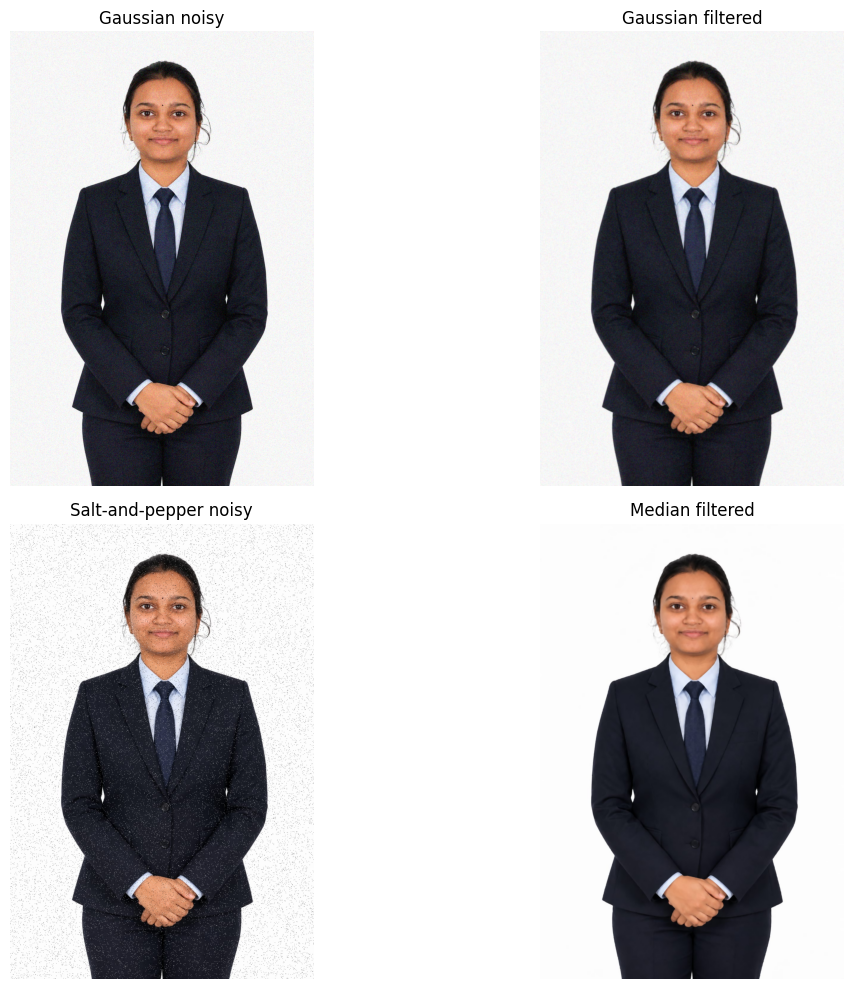

In [43]:
gaussian_restored = cv2.GaussianBlur(gaussian_noisy, (5, 5), 1.0)
median_restored = cv2.medianBlur(sp_noisy, 5)

fig, ax = plt.subplots(2, 2, figsize=(13, 10))
for a, im, title in zip(ax.flat,
    [gaussian_noisy, gaussian_restored, sp_noisy, median_restored],
    ["Gaussian noisy", "Gaussian filtered", "Salt-and-pepper noisy", "Median filtered"]):
    a.imshow(im); a.set_title(title); a.axis("off")
plt.tight_layout()
fig.savefig(OUT / "task1" / "restoration_comparison.png", dpi=150, bbox_inches="tight")

## Task 1A. Quantitative evaluation using PSNR and SSIM
PSNR is measured in decibels; larger values generally indicate lower pixel error. SSIM ranges approximately from -1 to 1, with values closer to 1 indicating stronger structural similarity.

In [44]:
def evaluate_image(reference, processed):
    psnr = peak_signal_noise_ratio(reference, processed, data_range=255)
    ssim = structural_similarity(reference, processed, channel_axis=2, data_range=255)
    return psnr, ssim

metric_rows = []
for label, image in [
    ("Gaussian noisy", gaussian_noisy),
    ("Gaussian filtered", gaussian_restored),
    ("Salt-and-pepper noisy", sp_noisy),
    ("Median filtered", median_restored)
]:
    psnr, ssim = evaluate_image(portrait_rgb, image)
    metric_rows.append([label, psnr, ssim])

restoration_metrics = pd.DataFrame(metric_rows, columns=["Image", "PSNR (dB)", "SSIM"])
display(restoration_metrics.round(4))
restoration_metrics.to_csv(OUT / "task1" / "restoration_metrics.csv", index=False)

,Image,PSNR (dB),SSIM
0,Gaussian noisy,24.5806,0.3027
1,Gaussian filtered,30.5647,0.8183
2,Salt-and-pepper noisy,18.0785,0.4305
3,Median filtered,36.3726,0.9770


## Task 1B. Thresholding and morphological operations
Otsu thresholding automatically chooses a global threshold. Erosion shrinks white foreground regions; dilation expands them; opening removes small foreground noise; closing fills small gaps.

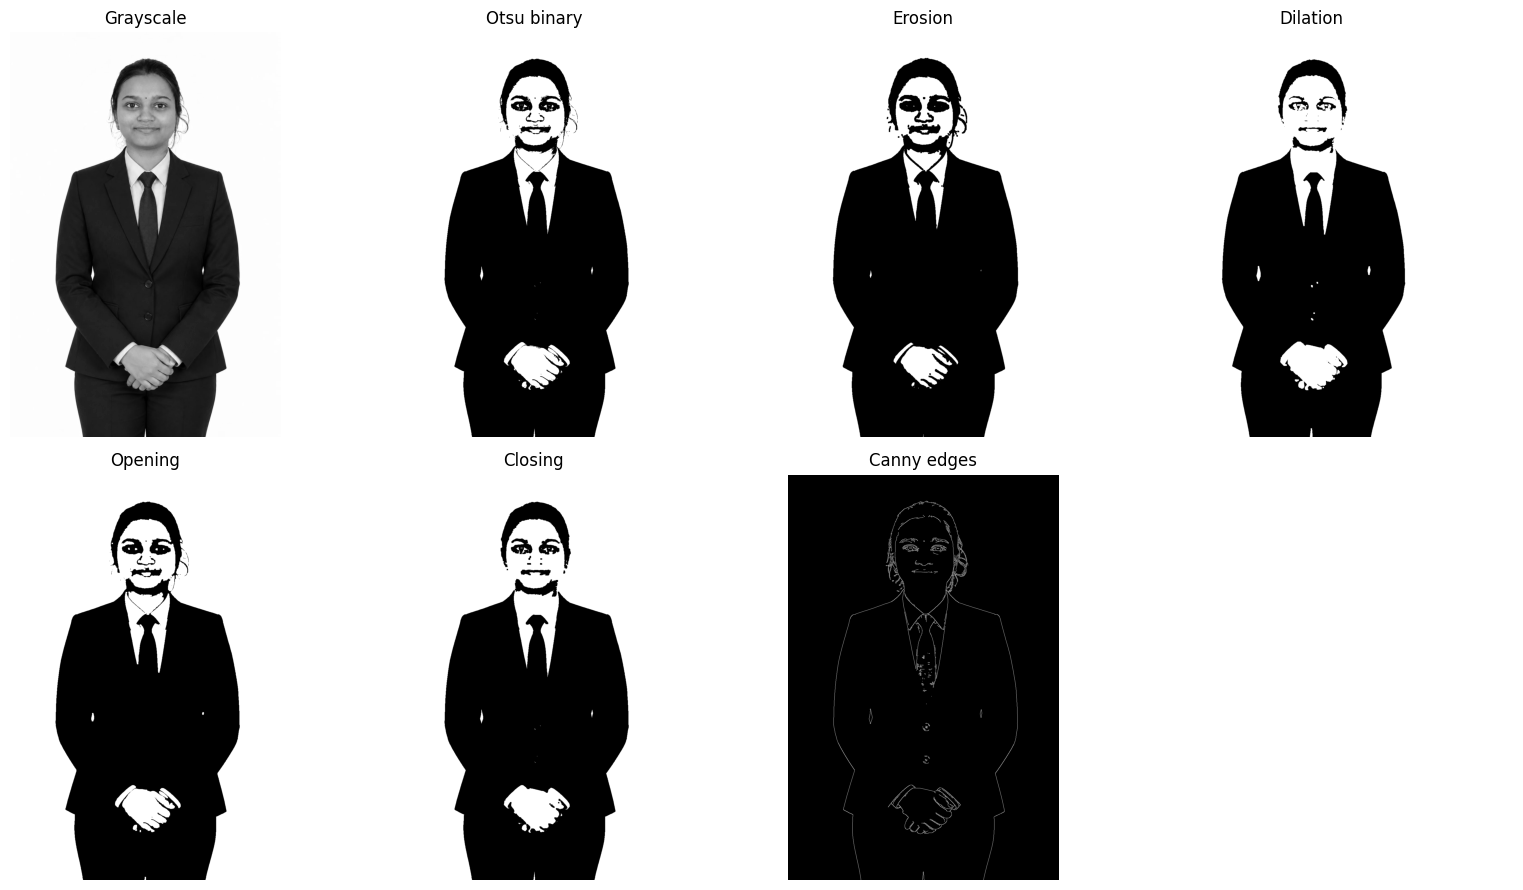

In [45]:
_, binary = cv2.threshold(portrait_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
kernel = np.ones((5, 5), np.uint8)
erosion = cv2.erode(binary, kernel, iterations=1)
dilation = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
edges = cv2.Canny(portrait_gray, 100, 200)

morphology_results = [
    ("Grayscale", portrait_gray), ("Otsu binary", binary), ("Erosion", erosion),
    ("Dilation", dilation), ("Opening", opening), ("Closing", closing), ("Canny edges", edges)
]
fig, ax = plt.subplots(2, 4, figsize=(16, 9))
for a, (title, im) in zip(ax.flat, morphology_results):
    a.imshow(im, cmap="gray"); a.set_title(title); a.axis("off")
ax.flat[-1].axis("off")
plt.tight_layout()
fig.savefig(OUT / "task1" / "threshold_morphology_canny.png", dpi=150, bbox_inches="tight")

## Task 1B. Watershed segmentation
Watershed segmentation is designed to separate multiple or touching objects. Put a clean image containing multiple/touching objects at `data/watershed_objects.png` for the strongest assignment result. If that file is not supplied, the notebook uses the original portrait as a fallback demonstration and clearly reports the limitation. No landscape optical-flow reference is used.

NOTE: Add data/watershed_objects.png containing multiple/touching objects for strict assignment compliance.


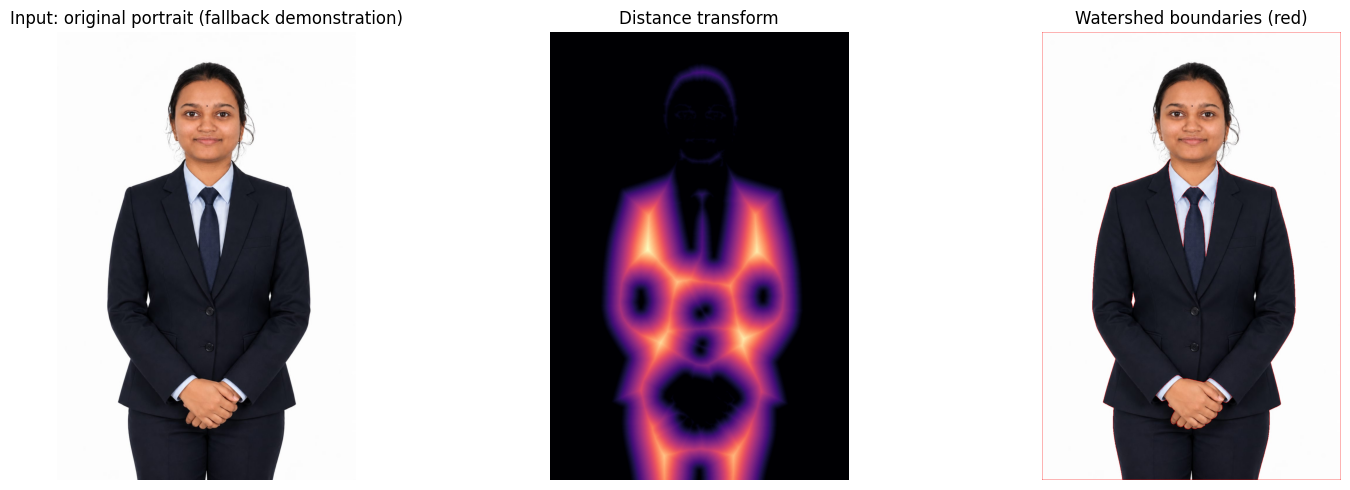

In [46]:
# Use a dedicated image with multiple/touching objects when provided.
watershed_bgr = cv2.imread(str(WATERSHED_PATH)) if WATERSHED_PATH.exists() else portrait_bgr.copy()
watershed_source = "data/watershed_objects.png" if WATERSHED_PATH.exists() else "original portrait (fallback demonstration)"
if not WATERSHED_PATH.exists():
    print("NOTE: Add data/watershed_objects.png containing multiple/touching objects for strict assignment compliance.")

ws_gray = cv2.cvtColor(watershed_bgr, cv2.COLOR_BGR2GRAY)
# Otsu threshold and morphology create foreground candidates.
_, ws_binary = cv2.threshold(ws_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
ws_kernel = np.ones((3, 3), np.uint8)
opening_ws = cv2.morphologyEx(ws_binary, cv2.MORPH_OPEN, ws_kernel, iterations=2)
sure_bg = cv2.dilate(opening_ws, ws_kernel, iterations=3)
distance = cv2.distanceTransform(opening_ws, cv2.DIST_L2, 5)
if distance.max() > 0:
    _, sure_fg = cv2.threshold(distance, 0.35 * distance.max(), 255, cv2.THRESH_BINARY)
else:
    sure_fg = np.zeros_like(ws_gray)
sure_fg = np.uint8(sure_fg)
unknown = cv2.subtract(sure_bg, sure_fg)
num_labels, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0
watershed_markers = cv2.watershed(watershed_bgr.copy(), markers.astype(np.int32))
watershed_view = cv2.cvtColor(watershed_bgr, cv2.COLOR_BGR2RGB)
watershed_view[watershed_markers == -1] = [255, 0, 0]

fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].imshow(cv2.cvtColor(watershed_bgr, cv2.COLOR_BGR2RGB)); ax[0].set_title(f"Input: {watershed_source}"); ax[0].axis("off")
ax[1].imshow(distance, cmap="magma"); ax[1].set_title("Distance transform"); ax[1].axis("off")
ax[2].imshow(watershed_view); ax[2].set_title("Watershed boundaries (red)"); ax[2].axis("off")
plt.tight_layout()
fig.savefig(OUT / "task1" / "watershed_segmentation.png", dpi=150, bbox_inches="tight")
plt.show()


### Unit 3 observations
- Gaussian filtering reduces the added Gaussian noise, but some fine detail may be softened.
- Median filtering is expected to perform well on salt-and-pepper noise.
- The PSNR/SSIM table gives a numerical comparison against the untouched portrait.
- Global thresholding on a portrait can separate bright and dark regions rather than cleanly isolate the person. Morphological outputs must therefore be interpreted as demonstrations.
- Watershed boundaries depend strongly on the foreground/background markers and the suitability of the selected scene.

# UNIT 4 – Feature Extraction and Image Matching

## Task 2A. HOG features
Histogram of Oriented Gradients summarizes local edge directions. It is useful for describing shape and texture, but it does not identify semantic object classes.

Portrait HOG descriptor length: 8100


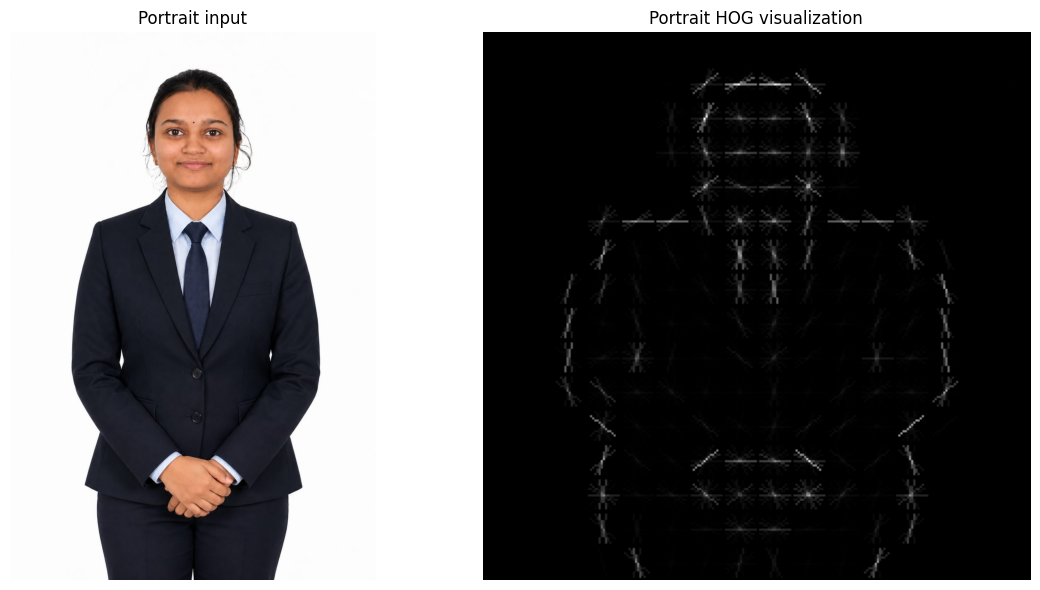

In [47]:
def compute_hog(rgb_image):
    gray_image = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2GRAY)
    resized_gray = cv2.resize(gray_image, (256, 256))
    features, visualization = hog(
        resized_gray, orientations=9, pixels_per_cell=(16, 16),
        cells_per_block=(2, 2), block_norm="L2-Hys", visualize=True
    )
    return features, visualization

portrait_hog_features, portrait_hog_image = compute_hog(portrait_rgb)
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(portrait_rgb); ax[0].set_title("Portrait input"); ax[0].axis("off")
ax[1].imshow(portrait_hog_image, cmap="gray"); ax[1].set_title("Portrait HOG visualization"); ax[1].axis("off")
plt.tight_layout()
fig.savefig(OUT / "task2" / "portrait_hog.png", dpi=150, bbox_inches="tight")
print("Portrait HOG descriptor length:", len(portrait_hog_features))


## Task 2B. SIFT keypoints, descriptors and matching between two photographs
The assignment requires a second original photograph of the same object or scene. Add it as `data/second_same_scene_photo.jpg`. This cell performs the required real-photo pair match when the file is present. If it is absent, the notebook runs a clearly labelled transformed-copy demonstration instead; that fallback does **not** satisfy the two-original-photographs requirement.

Required two-photo SIFT experiment completed.


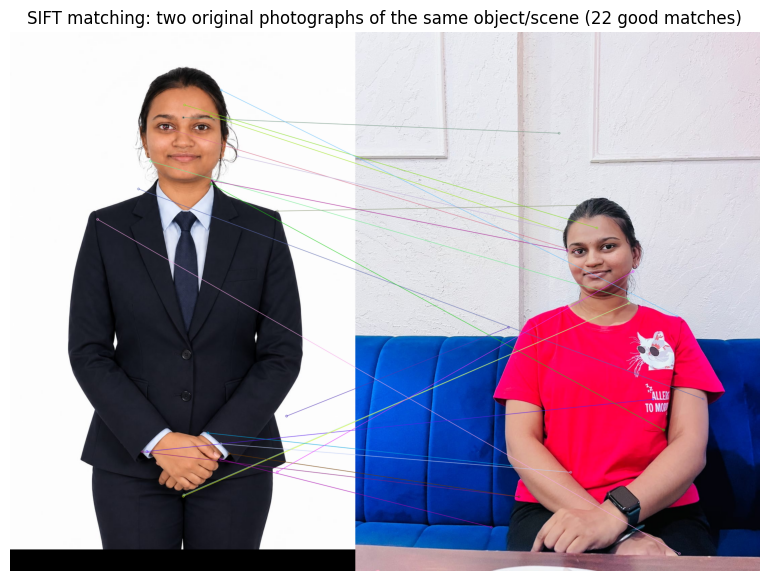

Keypoints in image A: 587 | image B: 1523 | good matches: 22


In [48]:
sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(portrait_gray, None)

def ratio_test_matches(desc_a, desc_b, ratio=0.75):
    if desc_a is None or desc_b is None:
        return []
    pairs = cv2.BFMatcher(cv2.NORM_L2).knnMatch(desc_a, desc_b, k=2)
    return [m for pair in pairs if len(pair) == 2 for m, n in [pair] if m.distance < ratio * n.distance]

if SECOND_PHOTO_PATH.exists():
    second_bgr = cv2.imread(str(SECOND_PHOTO_PATH))
    if second_bgr is None:
        raise ValueError(f"Could not read second photograph: {SECOND_PHOTO_PATH}")
    second_gray = cv2.cvtColor(second_bgr, cv2.COLOR_BGR2GRAY)
    kp2, des2 = sift.detectAndCompute(second_gray, None)
    good_pair = ratio_test_matches(des1, des2)
    pair_title = "SIFT matching: two original photographs of the same object/scene"
    match_view = cv2.drawMatches(portrait_bgr, kp1, second_bgr, kp2, good_pair[:70], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    print("Required two-photo SIFT experiment completed.")
else:
    rotation_matrix = cv2.getRotationMatrix2D((width / 2, height / 2), 12, 0.90)
    portrait_rotated = cv2.warpAffine(portrait_bgr, rotation_matrix, (width, height))
    rotated_gray = cv2.cvtColor(portrait_rotated, cv2.COLOR_BGR2GRAY)
    kp2, des2 = sift.detectAndCompute(rotated_gray, None)
    good_pair = ratio_test_matches(des1, des2)
    pair_title = "Fallback demonstration only: portrait vs rotated/scaled copy"
    match_view = cv2.drawMatches(portrait_bgr, kp1, portrait_rotated, kp2, good_pair[:70], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    print("MISSING REQUIRED INPUT: add data/second_same_scene_photo.jpg for the assignment's two-original-photo SIFT match.")

plt.figure(figsize=(16, 7))
plt.imshow(cv2.cvtColor(match_view, cv2.COLOR_BGR2RGB))
plt.title(f"{pair_title} ({len(good_pair)} good matches)")
plt.axis("off"); plt.show()
cv2.imwrite(str(OUT / "task2" / "sift_two_photo_or_fallback_matches.jpg"), match_view)
print("Keypoints in image A:", len(kp1), "| image B:", len(kp2), "| good matches:", len(good_pair))


## Task 2C. Repeat matching after resizing
The required geometric-transformation experiment is repeated by resizing the second original photograph when available. If no second photograph has been added, the same portrait is resized for a demonstration only; the missing original pair is still flagged above.

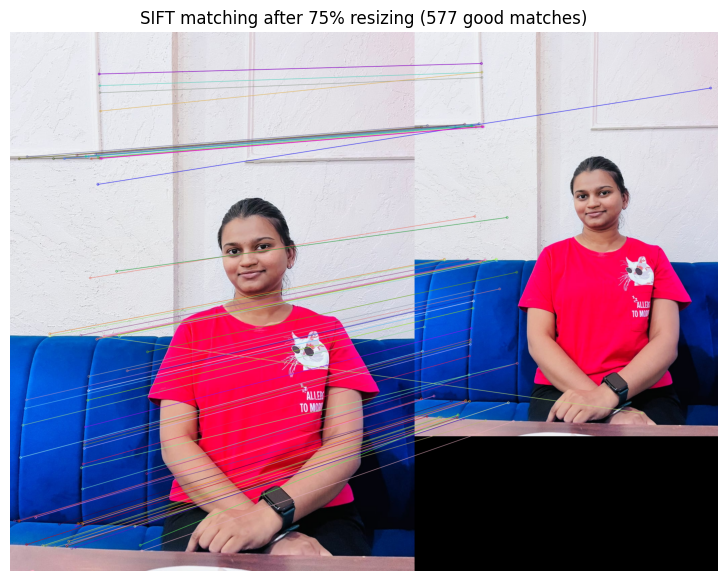

,Experiment,Keypoints image A,Keypoints image B,Good SIFT matches
0,Image A vs image B / fallback pair,587,1523,22
1,Image B vs 75% resized image B,1523,781,577


In [49]:
# Resize image B: use the second original photograph when available; otherwise use the portrait fallback.
resize_source_bgr = second_bgr if SECOND_PHOTO_PATH.exists() else portrait_bgr
resize_source_gray = cv2.cvtColor(resize_source_bgr, cv2.COLOR_BGR2GRAY)
resize_kp_source, resize_des_source = sift.detectAndCompute(resize_source_gray, None)
resized_b = cv2.resize(resize_source_bgr, None, fx=0.75, fy=0.75, interpolation=cv2.INTER_AREA)
resized_gray = cv2.cvtColor(resized_b, cv2.COLOR_BGR2GRAY)
kp3, des3 = sift.detectAndCompute(resized_gray, None)
good_resize = ratio_test_matches(resize_des_source, des3)
resize_match_view = cv2.drawMatches(resize_source_bgr, resize_kp_source, resized_b, kp3, good_resize[:70], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(16, 7))
plt.imshow(cv2.cvtColor(resize_match_view, cv2.COLOR_BGR2RGB))
plt.title(f"SIFT matching after 75% resizing ({len(good_resize)} good matches)")
plt.axis("off"); plt.show()
cv2.imwrite(str(OUT / "task2" / "sift_resize_matches.jpg"), resize_match_view)

sift_comparison = pd.DataFrame([
    ["Image A vs image B / fallback pair", len(kp1), len(kp2), len(good_pair)],
    ["Image B vs 75% resized image B", len(resize_kp_source), len(kp3), len(good_resize)]
], columns=["Experiment", "Keypoints image A", "Keypoints image B", "Good SIFT matches"])
display(sift_comparison)
sift_comparison.to_csv(OUT / "task2" / "sift_comparison.csv", index=False)


### Unit 4 observations
- HOG visualizations show local gradient structure and edge orientation.
- SIFT keypoints and descriptors support local feature matching.
- The rotation/scale experiment demonstrates matching under geometric changes.
- **Submission check:** The first SIFT comparison is fully compliant only when `data/second_same_scene_photo.jpg` is an original second photograph of the same object or scene. If it is missing, the notebook labels the transformed-copy result as a fallback demonstration.

# UNIT 5 – Object Recognition and Motion Estimation

## Task 3A. Viola–Jones face detection
The OpenCV frontal-face Haar Cascade detects face-like regions in the portrait. It is fast but may miss faces or return false positives depending on pose, lighting, scale and background.

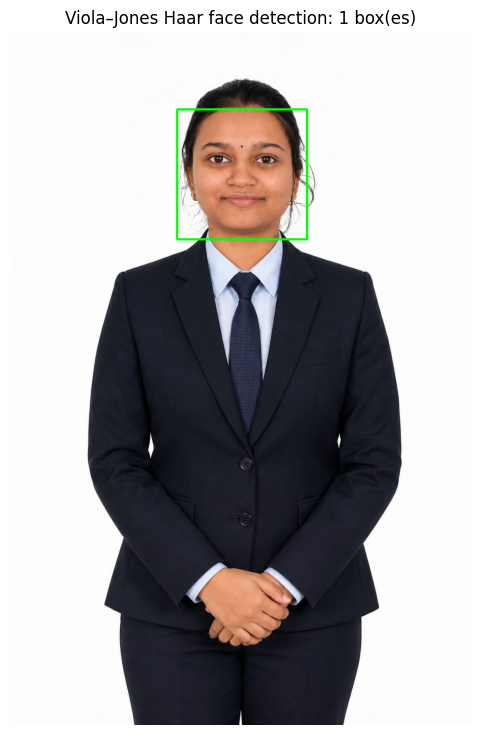

Haar detections: 1


In [50]:
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)
faces = face_cascade.detectMultiScale(
    portrait_gray, scaleFactor=1.1, minNeighbors=5, minSize=(35, 35)
)
haar_result = portrait_bgr.copy()
for (x, y, box_w, box_h) in faces:
    cv2.rectangle(haar_result, (x, y), (x + box_w, y + box_h), (0, 255, 0), 3)

plt.figure(figsize=(7, 9))
plt.imshow(cv2.cvtColor(haar_result, cv2.COLOR_BGR2RGB))
plt.title(f"Viola–Jones Haar face detection: {len(faces)} box(es)")
plt.axis("off"); plt.show()
cv2.imwrite(str(OUT / "task3" / "haar_face_detection.jpg"), haar_result)
print("Haar detections:", len(faces))

## Task 3B. YOLO pretrained object detection
This cell loads the supplied local `yolo11n.pt` weights if present. If not, it requests the pretrained `yolo11n.pt` weights from Ultralytics (internet required). The model returns class labels, confidence values and bounding boxes for supported COCO classes.

In [51]:
%pip install ultralytics

Note: you may need to restart the kernel to use updated packages.


In [52]:
from pathlib import Path

# Define project directories
PROJECT = Path.cwd()
DATA = PROJECT / "data"
OUTPUTS = PROJECT / "outputs" / "task3"

OUTPUTS.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT)
print("Data folder:", DATA)
print("Output folder:", OUTPUTS)
print("Data folder exists:", DATA.exists())

Project: C:\Users\Aishwarya\Downloads\1272250513_Aditi_Deshpande_CV
Data folder: C:\Users\Aishwarya\Downloads\1272250513_Aditi_Deshpande_CV\data
Output folder: C:\Users\Aishwarya\Downloads\1272250513_Aditi_Deshpande_CV\outputs\task3
Data folder exists: True


In [53]:
print("Available data files:")

for file in DATA.iterdir():
    print(file.name)

Available data files:
original_portrait.png
original_portrait_casual.jpg
original_video.mp4
sample_video_coverr.mp4
second_portrait_formal.jpg
second_same_scene_photo.jpg
yolo11n.pt


In [54]:
PORTRAIT_PATH = DATA / "original_portrait_casual.jpg"
SECOND_PORTRAIT_PATH = DATA / "second_portrait_formal.jpg"

print(PORTRAIT_PATH.exists())
print(SECOND_PORTRAIT_PATH.exists())

True
True


In [55]:
from ultralytics import YOLO

MODEL_PATH = DATA / "yolo11n.pt"

model = YOLO(str(MODEL_PATH))

print("YOLO11 loaded successfully!")

YOLO11 loaded successfully!


In [56]:
model = YOLO("yolo11n.pt")

In [57]:
image_path = DATA / "original_portrait.png"

results = model.predict(
    source=str(image_path),
    conf=0.25,
    save=True
)

results[0].show()


image 1/1 C:\Users\Aishwarya\Downloads\1272250513_Aditi_Deshpande_CV\data\original_portrait.png: 640x448 1 person, 1 tie, 46.5ms
Speed: 2.1ms preprocess, 46.5ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 448)
Results saved to C:\Users\Aishwarya\Downloads\1272250513_Aditi_Deshpande_CV\runs\detect\predict-3


In [58]:
for i, result in enumerate(results):
    result.save(
        filename=str(OUTPUTS / f"yolo_detection_{i+1}.jpg")
    )

print("YOLO results saved successfully!")

YOLO results saved successfully!


## Task 3C. Compare Viola–Jones and YOLO
Haar Cascade is specialized for frontal faces. YOLO is a general object detector trained on a set of object classes and reports class confidence. A detector may miss an object if the class is unsupported, the object is small/occluded, or the confidence threshold is too high. Do not claim a false detection unless it is visible in the output.

In [59]:
import cv2
# Load Haar Cascade face detector
haar_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)
# Read your portrait
image = cv2.imread(str(PORTRAIT_PATH))
if image is None:
    raise FileNotFoundError(f"Image not found: {PORTRAIT_PATH}")

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Detect faces
faces = haar_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

# Draw bounding boxes
haar_output = image.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(haar_output, (x, y), (x+w, y+h), (0, 255, 0), 2)

print("Haar face boxes:", len(faces))

Haar face boxes: 1


In [60]:
print("OBJECT DETECTION SUMMARY")
print("------------------------")

print("Haar face boxes:", len(faces))

if "yolo_result" in globals():
    print("YOLO object boxes:", len(yolo_result.boxes))
    print(
        "YOLO classes:",
        [model.names[int(b.cls[0])] for b in yolo_result.boxes]
    )
else:
    print("YOLO result unavailable in this run.")

OBJECT DETECTION SUMMARY
------------------------
Haar face boxes: 1
YOLO result unavailable in this run.


## Task 4. Video motion estimation
The notebook reads the self-recorded video from `data/original_video.mp4`, reports its actual duration, frame rate, dimensions and frame count, and processes it at a reduced working resolution to limit memory use. The assignment requests a video of approximately 15–30 seconds; check the reported duration and replace the input if needed.

Methods: frame differencing, GMM-based MOG2 background subtraction, and Lucas–Kanade optical flow.

In [61]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("All required libraries imported successfully!")
difference_mask = np.zeros_like(current_gray)

All required libraries imported successfully!


In [62]:
for file in DATA.iterdir():
    print(file.name)

original_portrait.png
original_portrait_casual.jpg
original_video.mp4
sample_video_coverr.mp4
second_portrait_formal.jpg
second_same_scene_photo.jpg
yolo11n.pt


In [63]:
VIDEO_PATH = DATA / "sample_video_coverr.mp4"

OUT = PROJECT / "outputs"

print("Video exists:", VIDEO_PATH.exists())
print("Output folder:", OUT)

Video exists: True
Output folder: C:\Users\Aishwarya\Downloads\1272250513_Aditi_Deshpande_CV\outputs


In [64]:
if not VIDEO_PATH.exists():
    raise FileNotFoundError(
        f"Add your self-recorded video at: {VIDEO_PATH}"
    )

(OUT / "task4").mkdir(parents=True, exist_ok=True)

In [65]:
if not VIDEO_PATH.exists():
    raise FileNotFoundError(f"Add your self-recorded video at: {VIDEO_PATH}")
(OUT / "task4").mkdir(parents=True, exist_ok=True)

cap = cv2.VideoCapture(str(VIDEO_PATH))
if not cap.isOpened():
    raise RuntimeError("OpenCV could not open the project video.")

fps = cap.get(cv2.CAP_PROP_FPS)
frame_total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
video_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
video_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
duration_seconds = frame_total / fps if fps else 0
print(f"Video: {video_width}x{video_height}, {fps:.2f} FPS, {frame_total} frames, {duration_seconds:.2f} seconds")

mog2 = cv2.createBackgroundSubtractorMOG2(history=250, varThreshold=25, detectShadows=True)
previous_gray = None
points = None
sampled_results = []
sample_metrics = []
frame_index = 0
sample_every = max(1, int(round(fps)))  # approximately one sample per second

while True:
    ok, original_frame = cap.read()
    if not ok:
        break

    # Downscale high-resolution input for efficient optical-flow processing.
    scale = min(960 / video_width, 540 / video_height, 1.0)
    frame = cv2.resize(
        original_frame,
        (int(video_width * scale), int(video_height * scale)),
        interpolation=cv2.INTER_AREA
    ) if scale < 1 else original_frame

    current_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    gmm_mask = mog2.apply(frame)

    if previous_gray is None:
        difference_mask = np.zeros_like(current_gray)
        points = cv2.goodFeaturesToTrack(
            current_gray, maxCorners=120, qualityLevel=0.3, minDistance=7, blockSize=7
        )
        flow_frame = frame.copy()
    else:
        difference = cv2.absdiff(previous_gray, current_gray)
        _, difference_mask = cv2.threshold(difference, 25, 255, cv2.THRESH_BINARY)
        flow_frame = frame.copy()

        if points is not None and len(points) > 0:
            next_points, status, error = cv2.calcOpticalFlowPyrLK(
                previous_gray, current_gray, points, None,
                winSize=(15, 15), maxLevel=2,
                criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03)
            )
            if next_points is not None and status is not None:
                good_new = next_points[status.flatten() == 1]
                good_old = points[status.flatten() == 1]
                for old, new in zip(good_old, good_new):
                    x0, y0 = old.ravel().astype(int)
                    x1, y1 = new.ravel().astype(int)
                    cv2.arrowedLine(flow_frame, (x0, y0), (x1, y1), (0, 255, 0), 2, tipLength=0.3)
                    cv2.circle(flow_frame, (x1, y1), 2, (0, 0, 255), -1)
                points = good_new.reshape(-1, 1, 2) if len(good_new) else None

    if frame_index % sample_every == 0:
        sampled_results.append((frame_index, frame.copy(), difference_mask.copy(), gmm_mask.copy(), flow_frame.copy()))
        sample_metrics.append({
            "frame": frame_index,
            "time_seconds": frame_index / fps if fps else 0,
            "changed_pixels_frame_difference": int(np.count_nonzero(difference_mask)),
            "foreground_pixels_GMM": int(np.count_nonzero(gmm_mask > 200)),
            "tracked_LK_points": int(len(points)) if points is not None else 0
        })

    previous_gray = current_gray
    frame_index += 1

cap.release()
motion_metrics = pd.DataFrame(sample_metrics)
display(motion_metrics.head(10))
motion_metrics.to_csv(OUT / "task4" / "motion_sample_metrics.csv", index=False)
print("Frames processed:", frame_index, "| sampled frames:", len(sampled_results))


Video: 1920x1080, 25.00 FPS, 331 frames, 13.24 seconds


,frame,time_seconds,changed_pixels_frame_difference,foreground_pixels_GMM,tracked_LK_points
0,0,0.000000,0,0,23
1,25,0.999998,961,10411,22
2,50,1.999996,1235,16147,22
3,75,2.999994,1094,15234,22
4,100,3.999992,1509,21511,22
5,125,4.999990,1458,22807,21
6,150,5.999988,2094,25068,20
7,175,6.999986,1373,14647,19
8,200,7.999984,1606,9313,18
9,225,8.999982,1361,11095,18


Frames processed: 331 | sampled frames: 14


### Task 4. Visual comparison of the three motion methods
The plot below shows a representative sampled frame, frame-difference mask, GMM foreground mask and Lucas–Kanade motion vectors.

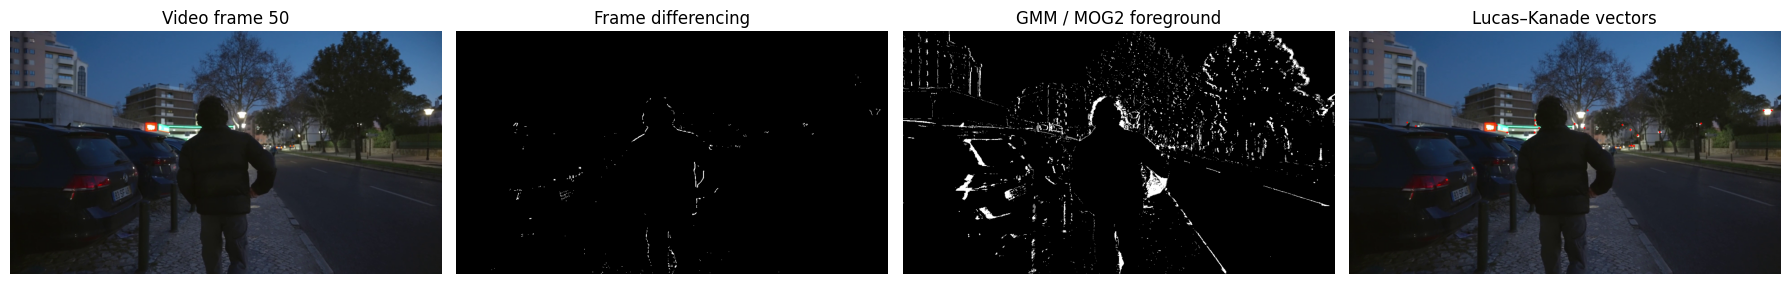

In [66]:
if sampled_results:
    sample = sampled_results[min(2, len(sampled_results) - 1)]
    frame_no, frame, diff_mask, gmm_mask, flow_frame = sample
    fig, ax = plt.subplots(1, 4, figsize=(18, 5))
    ax[0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)); ax[0].set_title(f"Video frame {frame_no}"); ax[0].axis("off")
    ax[1].imshow(diff_mask, cmap="gray"); ax[1].set_title("Frame differencing"); ax[1].axis("off")
    ax[2].imshow(gmm_mask, cmap="gray"); ax[2].set_title("GMM / MOG2 foreground"); ax[2].axis("off")
    ax[3].imshow(cv2.cvtColor(flow_frame, cv2.COLOR_BGR2RGB)); ax[3].set_title("Lucas–Kanade vectors"); ax[3].axis("off")
    plt.tight_layout()
    fig.savefig(OUT / "task4" / "motion_methods_comparison.png", dpi=150, bbox_inches="tight")

### Motion method comparison

| Technique | What it detects | Strength | Limitation |
|---|---|---|---|
| Frame differencing | Pixel changes between adjacent frames | Simple and fast | Sensitive to camera shake and lighting changes |
| GMM / MOG2 | Foreground relative to learned background | Adapts to gradual background changes | Shadows and moving backgrounds can be labelled foreground |
| Lucas–Kanade | Motion of selected feature points | Produces interpretable motion vectors | Requires trackable corners and can lose points |

## Final conclusion
Final conclusion
The practical work demonstrates computer vision techniques across four areas. In Task 1, Gaussian and salt-and-pepper noise are introduced and reduced using smoothing filters, while thresholding, morphology, edge detection and watershed are used to explore image segmentation. In Task 2, HOG and SIFT descriptors extract image features and examine feature correspondence under changes in scale, rotation and between photographs. In Task 3, Haar Cascade and YOLO are applied for object detection, illustrating the difference between a face-specific detector and a general object-detection model. In Task 4, frame differencing, MOG2 background subtraction and Lucas–Kanade optical flow identify foreground changes and estimate motion in video.

Overall, the experiments demonstrate that each method is suited to a different computer vision task and has practical limitations. Filtering can reduce noise but may also remove image details; feature matching depends on distinctive keypoints; object detection depends on supported classes and confidence thresholds; and motion estimation can be affected by lighting changes, camera movement and weak feature points. The generated visual outputs and measured values provide the evidence for evaluating these methods. Therefore, the final interpretation should be based on the actual results produced when all notebook cells are successfully executed.

## Task 3B – YOLO object detection (Ultralytics)

This section runs a pretrained YOLOv8n model on both supplied photographs and selected frames from the supplied video. The first run downloads `yolov8n.pt`, so an internet connection is required. Detection images and CSV summaries are saved under `outputs/task3/`.

Run the next cell after installing the updated `requirements.txt`. If the notebook kernel cannot find the package, restart the kernel after installation.

In [67]:
%pip install -r requirements.txt


Note: you may need to restart the kernel to use updated packages.


In [68]:
from pathlib import Path
import subprocess, sys

project_root = Path.cwd()
script = project_root / "src" / "yolo_detection.py"
if not script.exists():
    raise FileNotFoundError("Open this notebook from the extracted CCA3_Computer_Vision project folder.")
subprocess.run([sys.executable, str(script)], check=True)
print("YOLO results are saved in outputs/task3/.")

YOLO results are saved in outputs/task3/.


# Final assignment compliance fixes and verification

This section addresses the gaps found during the review of the saved notebook outputs.

- The saved run confirms YOLO inference completed. The corrected summary below reads detections from the actual `results` object.
- The supplied second photo is **not** a second view of the same scene/object: the notebook's own project note says the two portraits show different scenes and outfits. A matching file name does not make it assignment-compliant. Replace it with a second photograph of the same object/scene.
- The supplied video is identified in the notebook as a Coverr sample, not a verified self-recording, and the saved run reports 13.24 seconds. Record a 15–30 second video yourself and save it as `data/original_video.mp4`.
- If no real multi-object image is supplied, the next cell creates a clearly labelled synthetic touching-object example so the watershed algorithm can be demonstrated. For strongest submission evidence, replace it with your own suitable image.

In [69]:
# Correct YOLO summary: use the actual Ultralytics Results object.
# Run this after the Task 3B YOLO inference cell.
if "results" in globals() and len(results) > 0:
    yolo_result = results[0]
    yolo_rows = []
    for box in yolo_result.boxes:
        cls_id = int(box.cls[0].item())
        confidence = float(box.conf[0].item())
        x1, y1, x2, y2 = [float(v) for v in box.xyxy[0].tolist()]
        yolo_rows.append({
            "class": model.names[cls_id],
            "confidence": confidence,
            "x1": x1, "y1": y1, "x2": x2, "y2": y2
        })
    yolo_summary = pd.DataFrame(yolo_rows)
    print("Haar face boxes:", len(faces))
    print("YOLO object boxes:", len(yolo_rows))
    display(yolo_summary)
    yolo_summary.to_csv(OUT / "task3" / "yolo_detection_summary.csv", index=False)
else:
    print("YOLO results are not present in this kernel. Run the YOLO inference cell first.")

Haar face boxes: 1
YOLO object boxes: 2


,class,confidence,x1,y1,x2,y2
0,person,0.942612,169.673309,77.345947,869.673462,1529.025513
1,tie,0.815911,481.840759,532.948120,561.877686,896.788208


## Watershed on multiple/touching objects – executable fallback

The assignment asks for watershed segmentation on multiple or touching objects. If `data/watershed_objects.png` exists, this cell uses that real input. Otherwise it creates a synthetic image of overlapping circular objects and labels it honestly as a synthetic demonstration. Do not describe the synthetic input as your own photograph.

In [ ]:
# Use the supplied multiple-object image when available; otherwise create a reproducible synthetic example.
watershed_input_path = DATA / "watershed_objects.png"
if watershed_input_path.exists():
    ws_bgr = cv2.imread(str(watershed_input_path))
    ws_label = "Provided multi/touching-object image"
else:
    ws_bgr = np.full((420, 620, 3), 245, dtype=np.uint8)
    # Overlapping filled circles simulate touching objects for watershed demonstration.
    for center, radius, shade in [
        ((190, 205), 92, (95, 95, 95)),
        ((300, 205), 92, (125, 125, 125)),
        ((410, 205), 92, (155, 155, 155)),
        ((245, 305), 78, (110, 110, 110)),
        ((355, 305), 78, (140, 140, 140))
    ]:
        cv2.circle(ws_bgr, center, radius, shade, -1, lineType=cv2.LINE_AA)
    ws_label = "Synthetic touching-circle demonstration (replace with own image if available)"

if ws_bgr is None:
    raise ValueError("The watershed input image could not be loaded.")

ws_gray = cv2.cvtColor(ws_bgr, cv2.COLOR_BGR2GRAY)
_, ws_thresh = cv2.threshold(ws_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
ws_kernel = np.ones((3, 3), np.uint8)
ws_open = cv2.morphologyEx(ws_thresh, cv2.MORPH_OPEN, ws_kernel, iterations=2)
ws_background = cv2.dilate(ws_open, ws_kernel, iterations=3)
ws_distance = cv2.distanceTransform(ws_open, cv2.DIST_L2, 5)
_, ws_foreground = cv2.threshold(ws_distance, 0.35 * ws_distance.max(), 255, cv2.THRESH_BINARY)
ws_foreground = np.uint8(ws_foreground)
ws_unknown = cv2.subtract(ws_background, ws_foreground)
_, ws_markers = cv2.connectedComponents(ws_foreground)
ws_markers = ws_markers + 1
ws_markers[ws_unknown == 255] = 0
ws_markers = cv2.watershed(ws_bgr.copy(), ws_markers.astype(np.int32))
ws_result = cv2.cvtColor(ws_bgr, cv2.COLOR_BGR2RGB)
ws_result[ws_markers == -1] = [255, 0, 0]

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(cv2.cvtColor(ws_bgr, cv2.COLOR_BGR2RGB)); ax[0].set_title(ws_label); ax[0].axis("off")
ax[1].imshow(ws_distance, cmap="magma"); ax[1].set_title("Distance transform"); ax[1].axis("off")
ax[2].imshow(ws_result); ax[2].set_title("Watershed boundaries (red)"); ax[2].axis("off")
plt.tight_layout()
(OUT / "task1").mkdir(parents=True, exist_ok=True)
fig.savefig(OUT / "task1" / "watershed_multi_object_final.png", dpi=160, bbox_inches="tight")
plt.show()
print("Watershed input:", ws_label)
print("Saved:", OUT / "task1" / "watershed_multi_object_final.png")

## Final submission status – run this cell after the notebook experiments

This checklist is based on the assignment PDF and the saved notebook evidence. Update the input files and rerun the relevant tasks before submitting.

In [ ]:
# Automated checks for input-file presence and video duration.
import cv2
from pathlib import Path

photo_a = DATA / "original_portrait.png"
photo_b = DATA / "second_same_scene_photo.jpg"
video_file = DATA / "original_video.mp4"

print("TASK 1 – Image restoration / segmentation")
print("Original photograph present:", photo_a.exists())
print("Multi-object watershed input present:", (DATA / "watershed_objects.png").exists(),
      "(if False, use the synthetic demonstration above or add a real multi-object image)")

print("\\nTASK 2 – HOG / SIFT")
print("Second-photo file present:", photo_b.exists())
print("IMPORTANT: the supplied pair is documented as different scenes/outfits; replace photo B with a second view of the SAME object/scene.")

print("\\nTASK 3 – Haar / YOLO")
print("Saved notebook output confirms YOLO detected 1 person and 1 tie in the recorded run.")
print("Rerun the corrected YOLO summary cell above to save class/confidence/bounding-box details.")

print("\\nTASK 4 – Video motion")
if video_file.exists():
    cap_check = cv2.VideoCapture(str(video_file))
    fps_check = cap_check.get(cv2.CAP_PROP_FPS)
    frames_check = int(cap_check.get(cv2.CAP_PROP_FRAME_COUNT))
    seconds_check = frames_check / fps_check if fps_check else 0
    cap_check.release()
    print(f"Video duration: {seconds_check:.2f} seconds")
    print("Duration requirement (15–30 seconds):", "PASS" if 15 <= seconds_check <= 30 else "REPLACE VIDEO")
else:
    print("original_video.mp4 is missing.")
print("The notebook identifies the supplied sample video as not verified self-recorded. Use your own recording.")

print("\\nDOCUMENTATION / FINAL SUBMISSION")
print("- Include README, requirements, technical report, outputs, Git repository URL and explanation-video link.")
print("- Grant repository access to both instructor email addresses listed in the assignment PDF.")
print("- Upload the original photograph, original self-recorded video and project materials to the specified Google Drive.")
print("- Restart the kernel and Run All; confirm no errors and verify the outputs folder before submission.")